In [ ]:
import json
import pandas as pd
import numpy as np

with open('ntrk1_variants_raw.json') as f:
    raw = json.load(f)

print(f"Loaded {len(raw)} raw variant records")
print(json.dumps(raw[0], indent=2)[:2000])

Loaded 1375 raw variant records
{
  "_id": "chr1:g.156851403C>T",
  "_score": 8.148894,
  "cadd": {
    "_license": "http://bit.ly/2TIuab9",
    "alt": "T",
    "anc": "C",
    "annotype": "CodingTranscript",
    "bstatistic": 640,
    "chmm": {
      "bivflnk": 0.0,
      "enh": 0.0,
      "enhbiv": 0.016,
      "het": 0.0,
      "quies": 0.11,
      "reprpc": 0.307,
      "reprpcwk": 0.496,
      "tssa": 0.0,
      "tssaflnk": 0.0,
      "tssbiv": 0.008,
      "tx": 0.0,
      "txflnk": 0.0,
      "txwk": 0.039,
      "znfrpts": 0.0
    },
    "chrom": 1,
    "consdetail": "missense",
    "consequence": "NON_SYNONYMOUS",
    "consscore": 7,
    "cpg": 0.08,
    "dna": {
      "helt": 2.0,
      "mgw": 0.55,
      "prot": -2.79,
      "roll": 0.39
    },
    "encode": {
      "exp": 287.7,
      "h3k27ac": 4.0,
      "h3k4me1": 11.72,
      "h3k4me3": 3.0,
      "nucleo": 0.7,
      "occ": 2,
      "p_val": {
        "comb": 2.29,
        "ctcf": 0.0,
        "dnas": 2.6,
        "fai

In [ ]:
print(json.dumps(raw[0].get('clinvar', 'NO CLINVAR FIELD'), indent=2))

# Check a few more records too, since ClinVar structure can vary
for i in range(5):
    cv = raw[i].get('clinvar')
    print(f"\n--- Record {i} ---")
    print(json.dumps(cv, indent=2)[:500] if cv else "No clinvar data")

{
  "_license": "http://bit.ly/2SQdcI0",
  "gene": {
    "id": "4914",
    "symbol": "NTRK1"
  },
  "rcv": {
    "accession": "RCV002600014",
    "clinical_significance": "Likely benign",
    "conditions": {
      "identifiers": {
        "medgen": "C0020074",
        "mondo": "MONDO:0009746",
        "omim": "256800",
        "orphanet": "642"
      },
      "name": "Hereditary insensitivity to pain with anhidrosis (CIPA)",
      "synonyms": [
        "INSENSITIVITY TO PAIN, CONGENITAL, WITH ANHIDROSIS",
        "FAMILIAL DYSAUTONOMIA, TYPE II",
        "NEUROPATHY, CONGENITAL SENSORY, WITH ANHIDROSIS",
        "HSAN 4",
        "Familial dysautonomia, type 2",
        "HSAN Type IV",
        "hereditary sensory and autonomic neuropathy type 4",
        "Hereditary Sensory and Autonomic Neuropathy Type IV"
      ]
    },
    "last_evaluated": "2024-02-22",
    "number_submitters": 1,
    "origin": "germline",
    "preferred_name": "NM_002529.4(NTRK1):c.2360C>T (p.Ala787Val)",
    "rev

In [ ]:
def get_gene_info(cadd):
    gene = cadd.get('gene')
    if gene is None:
        return {}
    if isinstance(gene, list):
        return gene[0] if gene else {}
    return gene

rows = []
for record in raw:
    cadd = record.get('cadd')
    if not cadd:
        continue

    rcvs = get_rcv_list(record)
    if not rcvs:
        continue
    sig_list = [r.get('clinical_significance', '') for r in rcvs]
    label = classify_significance(sig_list)
    if label is None:
        continue

    gene_info = get_gene_info(cadd)
    prot_info = gene_info.get('prot', {}) if isinstance(gene_info.get('prot'), dict) else {}
    cds_info = gene_info.get('cds', {}) if isinstance(gene_info.get('cds'), dict) else {}

    rows.append({
        'variant_id': record.get('_id'),
        'label': label,
        'clinical_significance': '; '.join(set(sig_list)),
        'consequence': cadd.get('consequence'),
        'consscore': cadd.get('consscore'),
        'cadd_phred': cadd.get('phred'),
        'grantham': cadd.get('grantham'),
        'gerp_rs': cadd.get('gerp', {}).get('rs') if isinstance(cadd.get('gerp'), dict) else None,
        'gerp_s': cadd.get('gerp', {}).get('s') if isinstance(cadd.get('gerp'), dict) else None,
        'protein_domain': prot_info.get('domain'),
        'rel_prot_pos': prot_info.get('rel_prot_pos'),
        'rel_cds_pos': cds_info.get('rel_cds_pos'),
        'exon': cadd.get('exon'),
        'fitcons': cadd.get('fitcons'),
    })

df = pd.DataFrame(rows)
print(f"Parsed {len(df)} labeled variants")
print(f"Pathogenic/Likely pathogenic: {(df['label']==1).sum()}")
print(f"Benign/Likely benign: {(df['label']==0).sum()}")
print(df.head(10))
print(df.dtypes)

Parsed 706 labeled variants
Pathogenic/Likely pathogenic: 99
Benign/Likely benign: 607
            variant_id  label  \
0  chr1:g.156851403C>T      0   
1  chr1:g.156834568T>C      0   
2  chr1:g.156838400C>A      0   
3  chr1:g.156838525G>C      0   
4  chr1:g.156848950G>A      0   
5  chr1:g.156849914G>A      1   
6  chr1:g.156850078C>T      0   
7  chr1:g.156838278G>A      1   
8  chr1:g.156838304C>T      0   
9  chr1:g.156844412T>C      0   

                             clinical_significance             consequence  \
0                                    Likely benign          NON_SYNONYMOUS   
1                                    Likely benign              SYNONYMOUS   
2                                    Likely benign              SYNONYMOUS   
3                                    Likely benign  [REGULATORY, INTRONIC]   
4                                    Likely benign              SYNONYMOUS   
5                                       Pathogenic          NON_SYNONYMOUS   
6  

In [ ]:
def flatten_consscore(val):
    if isinstance(val, list):
        return max(val)
    return val

def flatten_consequence(val):
    if isinstance(val, list):
        # Prioritize the more severe consequence
        priority = ['STOP_GAINED', 'STOP_LOST', 'CANONICAL_SPLICE', 'SPLICE_SITE',
                    'NON_SYNONYMOUS', 'SYNONYMOUS', 'REGULATORY', 'INTRONIC']
        for p in priority:
            if p in val:
                return p
        return val[0]
    return val

df['consscore'] = df['consscore'].apply(flatten_consscore).astype(float)
df['consequence'] = df['consequence'].apply(flatten_consequence)

print(df['consequence'].value_counts())
print()
print(df.isnull().sum())

consequence
SYNONYMOUS          424
NON_SYNONYMOUS       98
INTRONIC             94
SPLICE_SITE          32
STOP_GAINED          28
REGULATORY           23
CANONICAL_SPLICE      5
DOWNSTREAM            2
Name: count, dtype: int64

variant_id                 0
label                      0
clinical_significance      0
consequence                0
consscore                  0
cadd_phred                 0
grantham                 608
gerp_rs                  153
gerp_s                     0
protein_domain           208
rel_prot_pos             148
rel_cds_pos              148
exon                     148
fitcons                    0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# One-hot encode categorical features
df_model = df.copy()
df_model = pd.get_dummies(df_model, columns=['consequence', 'protein_domain'], dummy_na=True)

feature_cols = [c for c in df_model.columns if c not in
                ['variant_id', 'label', 'clinical_significance', 'exon']]

X = df_model[feature_cols]
y = df_model['label']

print(f"Features used: {feature_cols}")
print(f"Class balance: {y.value_counts().to_dict()}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    class_weight='balanced',  # handles the 1:6 imbalance
    random_state=42
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Benign', 'Pathogenic']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Features used: ['consscore', 'cadd_phred', 'grantham', 'gerp_rs', 'gerp_s', 'rel_prot_pos', 'rel_cds_pos', 'fitcons', 'consequence_CANONICAL_SPLICE', 'consequence_DOWNSTREAM', 'consequence_INTRONIC', 'consequence_NON_SYNONYMOUS', 'consequence_REGULATORY', 'consequence_SPLICE_SITE', 'consequence_STOP_GAINED', 'consequence_SYNONYMOUS', 'consequence_nan', 'protein_domain_lcompl', 'protein_domain_ndomain', 'protein_domain_sigp', 'protein_domain_nan']
Class balance: {0: 607, 1: 99}

--- Classification Report ---
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98       152
  Pathogenic       0.91      0.84      0.88        25

    accuracy                           0.97       177
   macro avg       0.94      0.91      0.93       177
weighted avg       0.97      0.97      0.97       177

ROC-AUC: 0.987

Confusion Matrix:
[[150   2]
 [  4  21]]


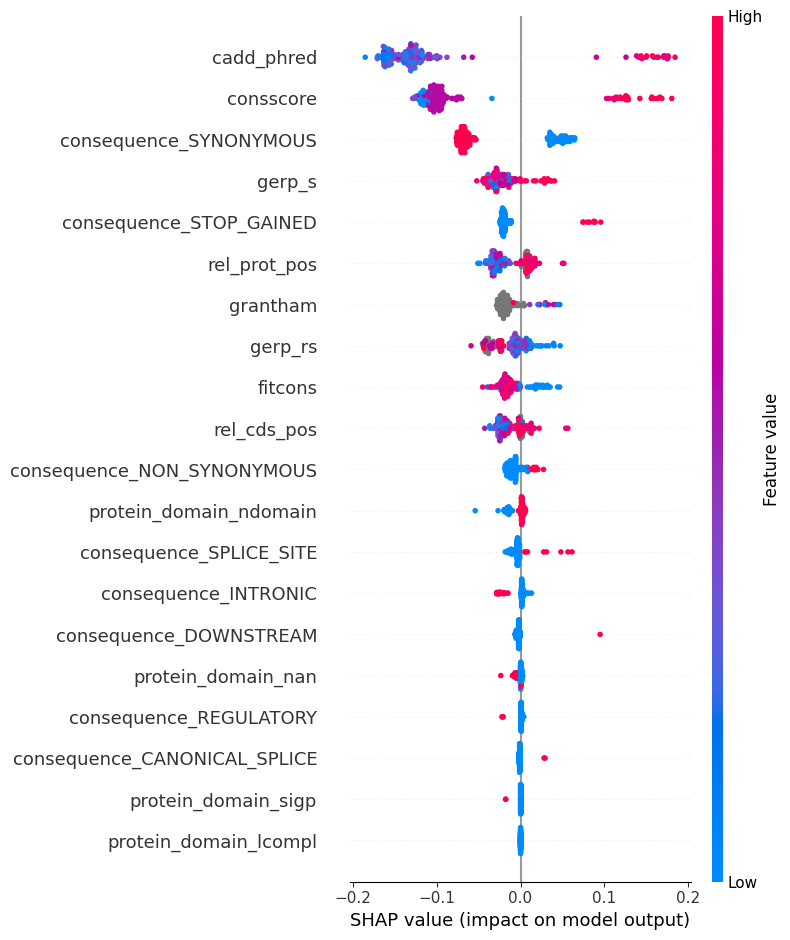

Top features by mean |SHAP value|:
                    feature  mean_abs_shap
1                cadd_phred       0.137731
0                 consscore       0.107272
15   consequence_SYNONYMOUS       0.058999
4                    gerp_s       0.026206
14  consequence_STOP_GAINED       0.023153
5              rel_prot_pos       0.020978
2                  grantham       0.020111
3                   gerp_rs       0.019562
7                   fitcons       0.017134
6               rel_cds_pos       0.014921


In [ ]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_test)

# For binary classification, shap_values can be a list [class0, class1] or a single array depending on version
if isinstance(shap_values, list):
    shap_vals_pathogenic = shap_values[1]
else:
    shap_vals_pathogenic = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

# Summary plot: which features drive pathogenicity predictions overall
plt.figure()
shap.summary_plot(shap_vals_pathogenic, X_test, show=False)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print("Top features by mean |SHAP value|:")
mean_abs_shap = pd.DataFrame({
    'feature': X_test.columns,
    'mean_abs_shap': np.abs(shap_vals_pathogenic).mean(axis=0)
}).sort_values('mean_abs_shap', ascending=False)
print(mean_abs_shap.head(10))

In [ ]:
!pip install scanpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 71.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.6 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take i

In [ ]:
import os
print(os.listdir('.'))

['.config', 'sample_data']


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving GSM5134537_prep1.csv to GSM5134537_prep1.csv


In [ ]:
import os
print(os.listdir('.'))

['.config', 'GSM5134539_prep3.csv', 'GSM5134541_prep5.csv', 'GSM5134540_prep4.csv', 'GSM5134542_prep6.csv', 'GSM5134537_prep1.csv', 'GSM5134538_prep2.csv', 'sample_data']


In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
import anndata as ad

sample_files = {
    'prep1': 'GSM5134537_prep1.csv.gz',
    'prep2': 'GSM5134538_prep2.csv.gz',
    'prep3': 'GSM5134539_prep3.csv.gz',
    'prep4': 'GSM5134540_prep4.csv.gz',
    'prep5': 'GSM5134541_prep5.csv.gz',
    'prep6': 'GSM5134542_prep6.csv.gz',
}

adatas = {}
for sample_name, fname in sample_files.items():
    df = pd.read_csv(fname, index_col=0)
    adata = ad.AnnData(X=df.T.values)
    adata.var_names = df.index.astype(str)
    adata.obs_names = [f"{sample_name}_{bc}" for bc in df.columns]
    adata.obs['sample'] = sample_name
    adatas[sample_name] = adata
    print(f"{sample_name}: {adata.shape[0]} cells, {adata.shape[1]} genes")

adata_combined = ad.concat(adatas.values(), join='outer', fill_value=0)
adata_combined.var_names_make_unique()
print(f"\nCombined: {adata_combined.shape[0]} cells, {adata_combined.shape[1]} genes")
print(adata_combined.obs['sample'].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: 'GSM5134537_prep1.csv.gz'

In [2]:
from google.colab import files
uploaded = files.upload()

Saving GSM5134542_prep6.csv to GSM5134542_prep6.csv
Saving GSM5134541_prep5.csv to GSM5134541_prep5.csv
Saving GSM5134540_prep4.csv to GSM5134540_prep4.csv
Saving GSM5134539_prep3.csv to GSM5134539_prep3.csv
Saving GSM5134538_prep2.csv to GSM5134538_prep2.csv
Saving GSM5134537_prep1.csv to GSM5134537_prep1.csv


In [3]:
import os
print(os.listdir('.'))

['.config', 'GSM5134539_prep3.csv', 'GSM5134541_prep5.csv', 'GSM5134540_prep4.csv', 'GSM5134542_prep6.csv', 'GSM5134537_prep1.csv', 'GSM5134538_prep2.csv', 'sample_data']


In [5]:
!pip install scanpy anndata

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.7 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take i

In [6]:
import scanpy as sc
import pandas as pd
import numpy as np
import anndata as ad

sample_files = {
    'prep1': 'GSM5134537_prep1.csv',
    'prep2': 'GSM5134538_prep2.csv',
    'prep3': 'GSM5134539_prep3.csv',
    'prep4': 'GSM5134540_prep4.csv',
    'prep5': 'GSM5134541_prep5.csv',
    'prep6': 'GSM5134542_prep6.csv',
}

adatas = {}
for sample_name, fname in sample_files.items():
    df = pd.read_csv(fname, index_col=0)
    adata = ad.AnnData(X=df.T.values)
    adata.var_names = df.index.astype(str)
    adata.obs_names = [f"{sample_name}_{bc}" for bc in df.columns]
    adata.obs['sample'] = sample_name
    adatas[sample_name] = adata
    print(f"{sample_name}: {adata.shape[0]} cells, {adata.shape[1]} genes")

adata_combined = ad.concat(adatas.values(), join='outer', fill_value=0)
adata_combined.var_names_make_unique()
print(f"\nCombined: {adata_combined.shape[0]} cells, {adata_combined.shape[1]} genes")
print(adata_combined.obs['sample'].value_counts())

prep1: 212 cells, 58188 genes
prep2: 152 cells, 58188 genes
prep3: 770 cells, 58188 genes
prep4: 281 cells, 58188 genes
prep5: 80 cells, 58188 genes
prep6: 342 cells, 58188 genes

Combined: 1837 cells, 58188 genes
sample
prep3    770
prep6    342
prep4    281
prep1    212
prep2    152
prep5     80
Name: count, dtype: int64


In [7]:
adata_combined.var['mt'] = adata_combined.var_names.str.startswith('MT-')
sc.pp.calculate_qc_metrics(adata_combined, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

print(adata_combined.obs[['n_genes_by_counts', 'total_counts', 'pct_counts_mt']].describe())

# Standard filtering thresholds for snRNA-seq
sc.pp.filter_cells(adata_combined, min_genes=200)
sc.pp.filter_genes(adata_combined, min_cells=3)
adata_combined = adata_combined[adata_combined.obs['pct_counts_mt'] < 10].copy()

print(f"\nAfter filtering: {adata_combined.shape[0]} cells, {adata_combined.shape[1]} genes")

       n_genes_by_counts  total_counts  pct_counts_mt
count        1837.000000   1837.000000    1837.000000
mean         2838.624388   7277.899292       2.630453
std          1916.643581   8687.845533       2.386160
min           501.000000    587.000000       0.000000
25%          1296.000000   1899.000000       0.828844
50%          2320.000000   4074.000000       1.810979
75%          4022.000000   9381.000000       3.794503
max          9652.000000  68463.000000       9.960159

After filtering: 1837 cells, 24948 genes


In [9]:
!pip install igraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 22.5 MB/s eta 0:00:00


In [11]:
# Fresh reload to avoid any double-processing
adatas = {}
for sample_name, fname in sample_files.items():
    df = pd.read_csv(fname, index_col=0)
    adata = ad.AnnData(X=df.T.values)
    adata.var_names = df.index.astype(str)
    adata.obs_names = [f"{sample_name}_{bc}" for bc in df.columns]
    adata.obs['sample'] = sample_name
    adatas[sample_name] = adata

adata_combined = ad.concat(adatas.values(), join='outer', fill_value=0)
adata_combined.var_names_make_unique()

# QC
adata_combined.var['mt'] = adata_combined.var_names.str.startswith('MT-')
sc.pp.calculate_qc_metrics(adata_combined, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

sc.pp.filter_cells(adata_combined, min_genes=200)
sc.pp.filter_genes(adata_combined, min_cells=3)
adata_combined = adata_combined[adata_combined.obs['pct_counts_mt'] < 10].copy()

# Remove any remaining zero-count cells (can appear after gene filtering)
sc.pp.filter_cells(adata_combined, min_counts=1)

print(f"After filtering: {adata_combined.shape[0]} cells, {adata_combined.shape[1]} genes")
print(f"Min total counts per cell: {adata_combined.X.sum(axis=1).min()}")

# Normalize (only once)
sc.pp.normalize_total(adata_combined, target_sum=1e4)
sc.pp.log1p(adata_combined)
adata_combined.raw = adata_combined

# HVG, PCA, clustering
sc.pp.highly_variable_genes(adata_combined, min_mean=0.0125, max_mean=3, min_disp=0.5)
adata_combined = adata_combined[:, adata_combined.var.highly_variable].copy()
sc.pp.scale(adata_combined, max_value=10)
sc.tl.pca(adata_combined, svd_solver='arpack')
sc.pp.neighbors(adata_combined, n_neighbors=15, n_pcs=30)
sc.tl.leiden(adata_combined, resolution=0.5, flavor='igraph', n_iterations=2, directed=False)
sc.tl.umap(adata_combined)

print(f"\nClusters found: {adata_combined.obs['leiden'].nunique()}")
print(adata_combined.obs['leiden'].value_counts())

After filtering: 1837 cells, 24948 genes
Min total counts per cell: 585

Clusters found: 14
leiden
5     250
4     204
3     198
0     179
7     156
8     152
2     150
12    132
13    122
9      84
10     71
11     61
6      51
1      27
Name: count, dtype: int64


True


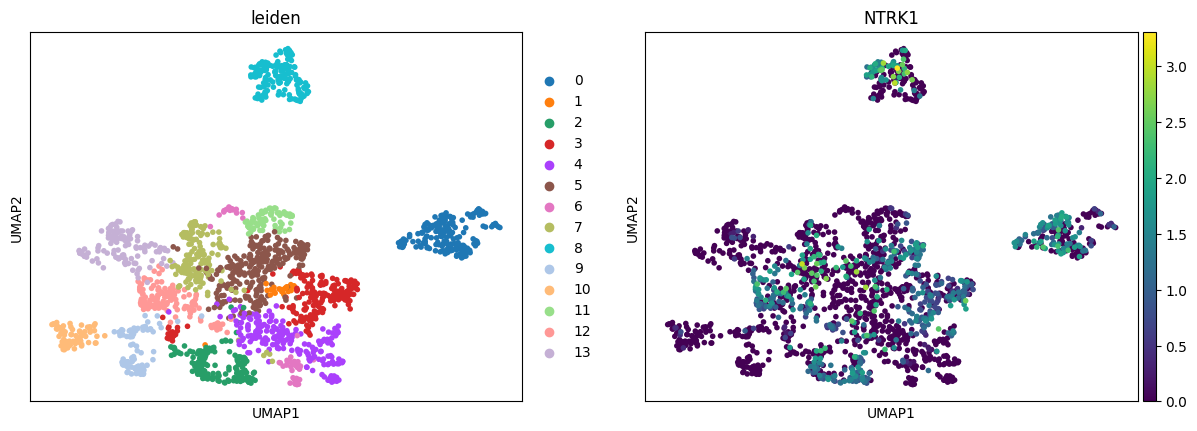

             mean  count
cluster                 
12       0.852381    132
0        0.754157    179
2        0.673204    150
8        0.659188    152
3        0.605439    198
5        0.467532    250
7        0.384618    156
4        0.196940    204
11       0.127084     61
1        0.113629     27
13       0.075783    122
6        0.052264     51
10       0.032844     71
9        0.019531     84


In [12]:
# Check NTRK1 is even in our filtered gene set
print('NTRK1' in adata_combined.raw.var_names)

# Plot NTRK1 expression across clusters
sc.pl.umap(adata_combined, color=['leiden', 'NTRK1'], use_raw=True, ncols=2)

# Quantify: mean NTRK1 expression per cluster
import pandas as pd
ntrk1_expr = adata_combined.raw[:, 'NTRK1'].X
if hasattr(ntrk1_expr, 'toarray'):
    ntrk1_expr = ntrk1_expr.toarray()
ntrk1_df = pd.DataFrame({
    'cluster': adata_combined.obs['leiden'].values,
    'NTRK1_expr': ntrk1_expr.flatten()
})
print(ntrk1_df.groupby('cluster')['NTRK1_expr'].agg(['mean', 'count']).sort_values('mean', ascending=False))

         0             1               2        3              4         5  \
0    PTGDS        SHISA6      AC159540.1    PCDH9           NRG1  HSP90AA1   
1     APOE         TENM2         CACNA1A  MSC-AS1          CSMD1     STMN2   
2   MT-CO3         NPTX2          MALAT1     DGKH          NEAT1      NEFL   
3      FTL        HPCAL1  CH507-528H12.1    TRPM3         MIR34A     YWHAG   
4   S100A6       KIRREL3            MIAT    NRXN1           KAZN     MAP1B   
5  MT-ATP6  CTC-535M15.2          AKAP12     DGKB       CACNA2D3      NEFM   
6    GAPDH  CTC-340A15.2           WDR60    NEGR1  CH17-125A10.2   MT-RNR2   
7      VIM          TAC1          LUC7L3  SLC44A5          DPP10     CALM1   
8   MT-ND4        DLGAP1           SRRM3  COL19A1         LHFPL3      SCOC   
9      SCD         NTRK2           TCF25     GPC6           DLG2      KLC1   

           6               7          8         9             10      11  \
0      PCDH7           PREPL   RASGEF1B    KCNIP4         SCN11A 

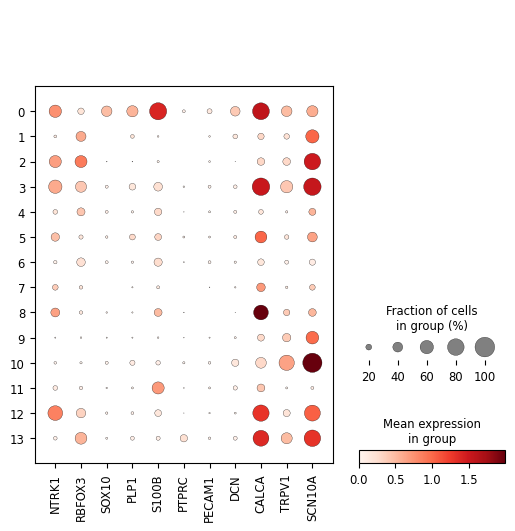


Sample composition per cluster:
sample  prep1  prep2  prep3  prep4  prep5  prep6
leiden                                          
0         179      0      0      0      0      0
1           1      0     25      1      0      0
2           0      0      0    148      2      0
3           5      0    192      0      0      1
4          25      0     92     28      3     56
5           1      0    215      6      2     26
6           1      0     29     13      4      4
7           0      0      0     20     44     92
8           0    152      0      0      0      0
9           0      0      4     45      0     35
10          0      0     69      0      2      0
11          0      0     61      0      0      0
12          0      0     17      0     17     98
13          0      0     66     20      6     30


In [13]:
sc.tl.rank_genes_groups(adata_combined, 'leiden', method='wilcoxon', use_raw=True)

# Top 10 markers per cluster
result = adata_combined.uns['rank_genes_groups']
groups = result['names'].dtype.names
markers_df = pd.DataFrame({group: result['names'][group][:10] for group in groups})
print(markers_df)

# Check specific marker genes to identify broad cell classes
check_genes = ['NTRK1', 'RBFOX3', 'SOX10', 'PLP1', 'S100B', 'PTPRC', 'PECAM1', 'DCN', 'CALCA', 'TRPV1', 'SCN10A']
check_genes_present = [g for g in check_genes if g in adata_combined.raw.var_names]
print(f"\nChecking: {check_genes_present}")

sc.pl.dotplot(adata_combined, check_genes_present, groupby='leiden', use_raw=True)

# Also check batch composition per cluster, to rule out donor-driven clustering
print("\nSample composition per cluster:")
print(pd.crosstab(adata_combined.obs['leiden'], adata_combined.obs['sample']))

In [14]:
# Confirm CALCA, SCN10A, GFRA2 patterns across all clusters, and flag batch purity
for gene in ['CALCA', 'SCN10A', 'GFRA2']:
    if gene in adata_combined.raw.var_names:
        expr = adata_combined.raw[:, gene].X
        if hasattr(expr, 'toarray'):
            expr = expr.toarray()
        tmp = pd.DataFrame({'cluster': adata_combined.obs['leiden'].values, 'expr': expr.flatten()})
        print(f"\n--- {gene} ---")
        print(tmp.groupby('cluster')['expr'].mean().sort_values(ascending=False).head(5))

# Quantify donor purity per cluster (what % of cluster comes from its dominant donor)
crosstab = pd.crosstab(adata_combined.obs['leiden'], adata_combined.obs['sample'])
purity = crosstab.max(axis=1) / crosstab.sum(axis=1)
print("\nDonor purity per cluster (1.0 = single donor only):")
print(purity.sort_values(ascending=False))


--- CALCA ---
cluster
8     1.990072
0     1.568013
3     1.508238
13    1.370935
12    1.294520
Name: expr, dtype: float32

--- SCN10A ---
cluster
10    1.989381
3     1.531045
2     1.479698
13    1.304677
12    1.047991
Name: expr, dtype: float32

--- GFRA2 ---
cluster
9     1.789610
10    1.504933
0     0.276608
5     0.208699
7     0.194754
Name: expr, dtype: float32

Donor purity per cluster (1.0 = single donor only):
leiden
0     1.000000
8     1.000000
11    1.000000
2     0.986667
10    0.971831
3     0.969697
1     0.925926
5     0.860000
12    0.742424
7     0.589744
6     0.568627
13    0.540984
9     0.535714
4     0.450980
dtype: float64


In [15]:
# Pull NTRK1 and GFRA2 expression per cell, directly, no cluster dependency
ntrk1 = adata_combined.raw[:, 'NTRK1'].X
gfra2 = adata_combined.raw[:, 'GFRA2'].X
calca = adata_combined.raw[:, 'CALCA'].X

for arr_name, arr in [('ntrk1', ntrk1), ('gfra2', gfra2), ('calca', calca)]:
    if hasattr(arr, 'toarray'):
        arr = arr.toarray()

expr_df = pd.DataFrame({
    'NTRK1': np.asarray(ntrk1.todense()).flatten() if hasattr(ntrk1, 'todense') else ntrk1.flatten(),
    'GFRA2': np.asarray(gfra2.todense()).flatten() if hasattr(gfra2, 'todense') else gfra2.flatten(),
    'CALCA': np.asarray(calca.todense()).flatten() if hasattr(calca, 'todense') else calca.flatten(),
    'sample': adata_combined.obs['sample'].values
})

# Correlation, independent of clustering
print(expr_df[['NTRK1', 'GFRA2', 'CALCA']].corr())

# Does the NTRK1 vs GFRA2 anti-correlation hold within each donor separately? (the real test)
for s in expr_df['sample'].unique():
    sub = expr_df[expr_df['sample'] == s]
    corr = sub['NTRK1'].corr(sub['GFRA2'])
    print(f"{s}: NTRK1 vs GFRA2 correlation = {corr:.3f} (n={len(sub)})")

          NTRK1     GFRA2     CALCA
NTRK1  1.000000 -0.167337  0.244221
GFRA2 -0.167337  1.000000 -0.176107
CALCA  0.244221 -0.176107  1.000000
prep1: NTRK1 vs GFRA2 correlation = -0.157 (n=212)
prep2: NTRK1 vs GFRA2 correlation = -0.059 (n=152)
prep3: NTRK1 vs GFRA2 correlation = -0.169 (n=770)
prep4: NTRK1 vs GFRA2 correlation = -0.255 (n=281)
prep5: NTRK1 vs GFRA2 correlation = -0.099 (n=80)
prep6: NTRK1 vs GFRA2 correlation = -0.163 (n=342)


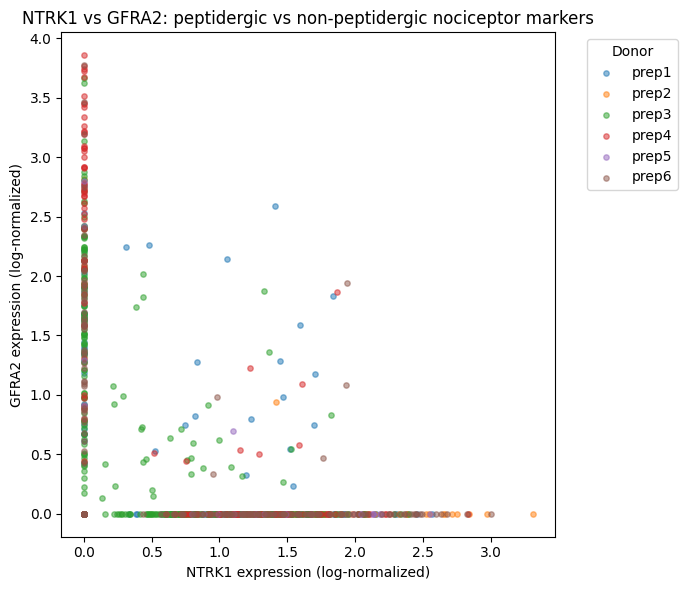

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
for s in expr_df['sample'].unique():
    sub = expr_df[expr_df['sample'] == s]
    ax.scatter(sub['NTRK1'], sub['GFRA2'], alpha=0.5, s=15, label=s)

ax.set_xlabel('NTRK1 expression (log-normalized)')
ax.set_ylabel('GFRA2 expression (log-normalized)')
ax.set_title('NTRK1 vs GFRA2: peptidergic vs non-peptidergic nociceptor markers')
ax.legend(title='Donor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('ntrk1_gfra2_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# Save the per-donor correlation table as a clean results CSV
corr_results = []
for s in expr_df['sample'].unique():
    sub = expr_df[expr_df['sample'] == s]
    corr_results.append({'donor': s, 'n_cells': len(sub), 'ntrk1_gfra2_corr': sub['NTRK1'].corr(sub['GFRA2'])})
pd.DataFrame(corr_results).to_csv('ntrk1_gfra2_correlation_by_donor.csv', index=False)

# Save the marker genes table
markers_df.to_csv('cluster_markers.csv', index=False)

from google.colab import files
files.download('ntrk1_gfra2_correlation.png')
files.download('ntrk1_gfra2_correlation_by_donor.csv')
files.download('cluster_markers.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>